# Benchmarks: WN18, FB15k and their harder versions

[01_introduction](01_introduction.ipynb) showed on three small graphs that KGCP's answer sets keep their coverage guarantee, and that the score decides how small they are. This notebook does the same on the four standard link prediction benchmarks, with up to 40,943 entities, using the KGE models that LibKGE's authors trained for them:

- **Datasets:** WN18 and FB15k, and their harder versions WN18RR (Dettmers et al., 2018) and FB15k-237 (Toutanova and Chen, 2015). The harder versions leave out the test triples that are easy to answer from a reverse triple in the training data.
- **Models:** RESCAL, TransE, DistMult, ComplEx, ConvE and RotatE, as published with [LibKGE](https://github.com/uma-pi1/kge#results-and-pretrained-models): one trained model per dataset, 24 in all, in `models/libkge/<dataset>-<model>.pt`. Their test metrics, as we evaluated them, are in `results/libkge/test.jsonl`.
- **Protocol:** the one of 01 and `scripts/conformal.py`. The candidates of a query are all entities except the answers known from train and valid; other test answers stay candidates. The six scores are calibrated on a random half of the test queries and evaluated on the other half, over 100 random splits. Unless stated otherwise, $\alpha = 0.1$ with marginal calibration (one threshold for all queries).

Scoring every candidate of every test query needs a GPU on these graphs (FB15k: 118,142 queries × 14,951 entities, and about 24 GB of memory for the scores of one score function). The results were therefore computed beforehand, on a Modal T4 GPU in about an hour for all 24 models, with

```bash
python scripts/conformal.py models/libkge/*.pt --device cuda --batch-size 64 --out results/conformal/libkge
```

(`--batch-size 64` fits RotatE on WN18RR into the T4's memory), and are read here from `results/conformal/libkge/`. Only the last part, *Why the harder versions need large sets*, loads models: four of them, on a laptop CPU, in under a minute.

| Dataset | Entities | Relations | Test triples | Queries | Calibration $n$ = test $m$ | Std of one split's coverage |
|---|---|---|---|---|---|---|
| WN18 | 40,943 | 18 | 5,000 | 10,000 | 5,000 | ≈ 0.0060 |
| FB15k | 14,951 | 1,345 | 59,071 | 118,142 | 59,071 | ≈ 0.0017 |
| WN18RR | 40,943 | 11 | 3,134 | 6,268 | 3,134 | ≈ 0.0076 |
| FB15k-237 | 14,541 | 237 | 20,466 | 40,932 | 20,466 | ≈ 0.0030 |

**No error bars.** `scripts/conformal.py` pools the 100 splits: a model's coverage is the fraction of all 100 × $m$ test queries whose set holds the true answer, and its set size is the mean over these queries. So the files hold no spread, and with one model per dataset there are no seeds either. For coverage, the spread is known: as in 01, the coverage of a single split varies with a standard deviation of about $\sqrt{\alpha(1-\alpha)(1/n + 1/m)}$, the last column above. That is 0.0017 to 0.0076 here, against 0.013 to 0.030 on the small graphs, and the mean over 100 splits varies less still. The coverage plots show it as a gray band around the target. For set size there is no such formula, so we only discuss differences of 10% or more.

In [1]:
import contextlib
import io
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

import kgcp

ROOT = Path.cwd().parent  # the notebook runs in notebooks/
DATASETS = {"wn18": "WN18", "fb15k": "FB15k", "wnrr": "WN18RR", "fb15k-237": "FB15k-237"}
TEST_TRIPLES = {"WN18": 5000, "FB15k": 59071, "WN18RR": 3134, "FB15k-237": 20466}
MODELS = {
    "rescal": "RESCAL",
    "transe": "TransE",
    "distmult": "DistMult",
    "complex": "ComplEx",
    "conve": "ConvE",
    "rotate": "RotatE",
}
SCORES = {
    "neg": "Neg",
    "minmax": "MinMax",
    "softmax": "Softmax",
    "aps": "APS",
    "raps": "RAPS",
    "rank": "Rank",
}
ALPHA = 0.1

# one row per model, score, grouping and alpha, with the metrics pooled over the 100 splits
files = sorted((ROOT / "results/conformal/libkge").glob("*-test.csv"))
results = pd.concat(map(pd.read_csv, files))
results = results.replace({"dataset": DATASETS, "model": MODELS, "score": SCORES})
marginal = results[(results.groups == "marginal") & (results.alpha == ALPHA)]
print(f"{len(files)} models, {len(results)} rows")

24 models, 1296 rows


## WN18 and FB15k

Coverage first, as in 01: each bar is a model's coverage at $\alpha = 0.1$, pooled over the 100 splits. The dashed line is the target $1 - \alpha = 0.9$, the gray band ± 1 standard deviation of a single split.

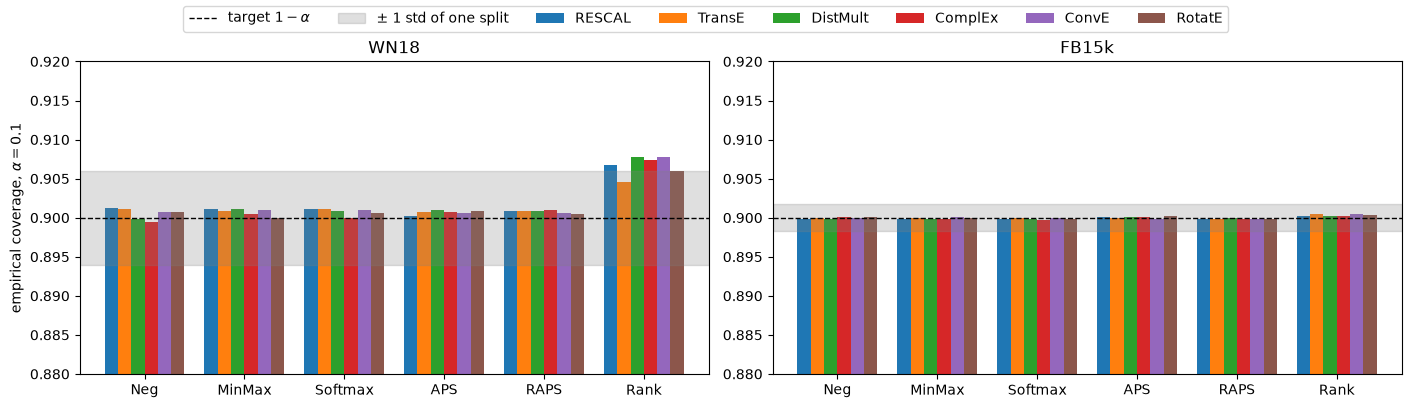

score               Neg MinMax Softmax    APS   RAPS   Rank
dataset model                                              
WN18    RESCAL    0.901  0.901   0.901  0.900  0.901  0.907
        TransE    0.901  0.901   0.901  0.901  0.901  0.905
        DistMult  0.900  0.901   0.901  0.901  0.901  0.908
        ComplEx   0.899  0.900   0.900  0.901  0.901  0.907
        ConvE     0.901  0.901   0.901  0.901  0.901  0.908
        RotatE    0.901  0.900   0.901  0.901  0.901  0.906
FB15k   RESCAL    0.900  0.900   0.900  0.900  0.900  0.900
        TransE    0.900  0.900   0.900  0.900  0.900  0.900
        DistMult  0.900  0.900   0.900  0.900  0.900  0.900
        ComplEx   0.900  0.900   0.900  0.900  0.900  0.900
        ConvE     0.900  0.900   0.900  0.900  0.900  0.900
        RotatE    0.900  0.900   0.900  0.900  0.900  0.900

In [2]:
def bars(datasets: list[str], metric: str, ylabel: str, log: bool = False):
    # A panel per dataset, a group of bars per score, a bar per model (alpha = 0.1,
    # marginal calibration). Returns the figure and the plotted values.
    data = marginal[marginal.dataset.isin(datasets)]
    table = data.pivot(index=["dataset", "model"], columns="score", values=metric)
    table = table.loc[
        pd.MultiIndex.from_product([datasets, MODELS.values()]), list(SCORES.values())
    ]
    fig, axes = plt.subplots(1, len(datasets), figsize=(14, 4), layout="constrained")
    for ax, dataset in zip(axes, datasets, strict=True):
        table.loc[dataset].T.plot.bar(ax=ax, rot=0, width=0.8, legend=False, logy=log)
        ax.set(title=dataset, xlabel="")
    axes[0].set_ylabel(ylabel)
    return fig, table


def plot_coverage(datasets: list[str]) -> pd.DataFrame:
    fig, table = bars(datasets, "coverage", rf"empirical coverage, $\alpha = {ALPHA}$")
    for ax, dataset in zip(fig.axes, datasets, strict=True):
        n = m = TEST_TRIPLES[dataset]  # calibration and test queries of a split
        std = math.sqrt(ALPHA * (1 - ALPHA) * (1 / n + 1 / m))
        ax.axhline(
            1 - ALPHA, color="black", linestyle="--", linewidth=1, label=r"target $1 - \alpha$"
        )
        ax.axhspan(
            1 - ALPHA - std, 1 - ALPHA + std, color="gray", alpha=0.25, label="± 1 std of one split"
        )
        ax.set_ylim(0.88, 0.92)
    fig.legend(*fig.axes[0].get_legend_handles_labels(), loc="outside upper center", ncols=8)
    plt.show()
    return table.map("{:.3f}".format)


def plot_size(datasets: list[str]) -> pd.DataFrame:
    fig, table = bars(datasets, "size", rf"mean set size, $\alpha = {ALPHA}$ (log scale)", log=True)
    fig.legend(*fig.axes[0].get_legend_handles_labels(), loc="outside upper center", ncols=6)
    plt.show()
    return table.map("{:,.1f}".format)


plot_coverage(["WN18", "FB15k"])

Apart from Rank on WN18, all bars are within one standard deviation of a split from the target: 0.900 for every model and score on FB15k, and 0.899 to 0.901 on WN18.

Rank over-covers on WN18, 0.905 to 0.908, for the reason seen in 01. Its sets are the top $k$ candidates for a whole number $k$, and on WN18 that number is 2: for ComplEx, the top candidate alone holds the true answer of 86% of the queries, the top two of about 91% (see the ranks in part 2 below), so no $k$ gives 0.90. On FB15k, $k$ is about 50, and one candidate more or less changes the coverage little.

Set sizes next, on a log scale: on the same two graphs, they span four orders of magnitude.

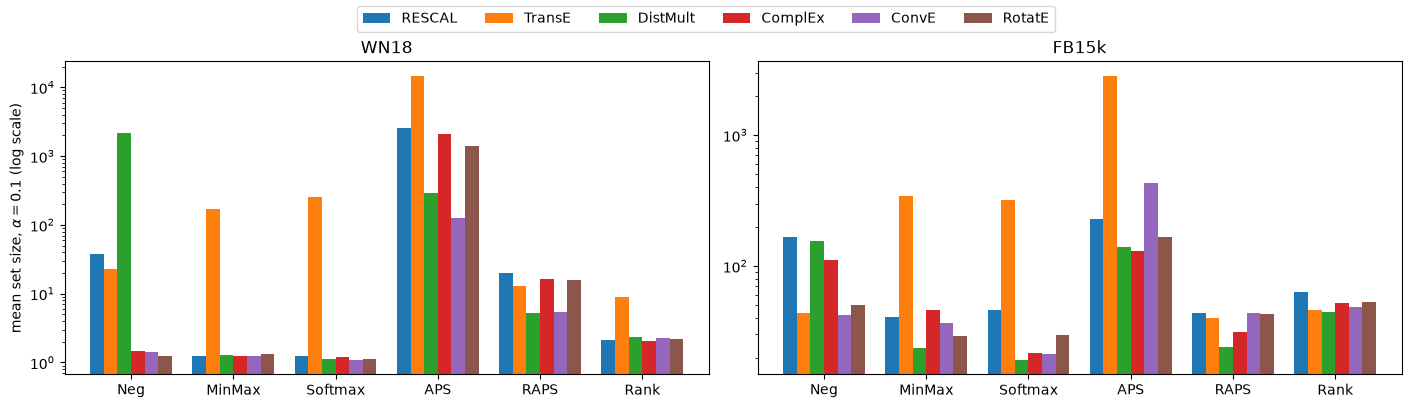

score                 Neg MinMax Softmax       APS  RAPS  Rank
dataset model                                                 
WN18    RESCAL       37.4    1.2     1.2   2,579.1  19.8   2.1
        TransE       22.7  171.9   258.0  14,790.7  13.0   8.9
        DistMult  2,202.4    1.3     1.1     290.8   5.2   2.3
        ComplEx       1.5    1.2     1.2   2,067.7  16.5   2.0
        ConvE         1.4    1.2     1.1     126.8   5.5   2.3
        RotatE        1.3    1.3     1.1   1,420.2  15.9   2.2
FB15k   RESCAL      166.8   41.1    45.8     228.2  43.6  63.5
        TransE       43.6  341.6   317.3   2,841.8  39.8  45.9
        DistMult    155.5   23.9    19.2     139.6  24.2  44.3
        ComplEx     110.8   45.8    21.8     130.4  31.3  51.8
        ConvE        42.1   36.6    21.5     433.6  43.5  48.6
        RotatE       50.5   29.3    29.7     165.7  43.3  53.3

In [3]:
plot_size(["WN18", "FB15k"])

- **Small sets on both graphs.** With Softmax, a WN18 set holds 1.1 to 1.2 of the 40,943 entities for five of the six models, and an FB15k set 19 to 46 of the 14,951 entities. As on the small graphs of 01, Softmax gives the smallest sets, or sets within 12% of the smallest (MinMax), for every model but TransE.
- **TransE** is the exception: its Softmax and MinMax sets hold 172 to 342 entities. Rank and RAPS, whose scores grow with the rank, suit it better: 8.9 and 13.0 entities on WN18, 45.9 and 39.8 on FB15k.
- **APS** gives the largest sets on both graphs, up to 14,791 entities (TransE on WN18). It scores a candidate by the probability mass ranked above it, so a threshold close to 1 takes in thousands of entities that each carry almost no mass. RAPS adds 0.01 per rank beyond the fifth and shrinks APS's sets by a factor of 4 to over 1,000.
- **Neg** depends on the model: 1.3 to 1.5 entities for ComplEx, ConvE and RotatE on WN18, but 2,202 for DistMult. As explained in 01, one threshold on raw logits needs logits that are comparable across queries.

## WN18RR and FB15k-237

The same plots for the harder versions.

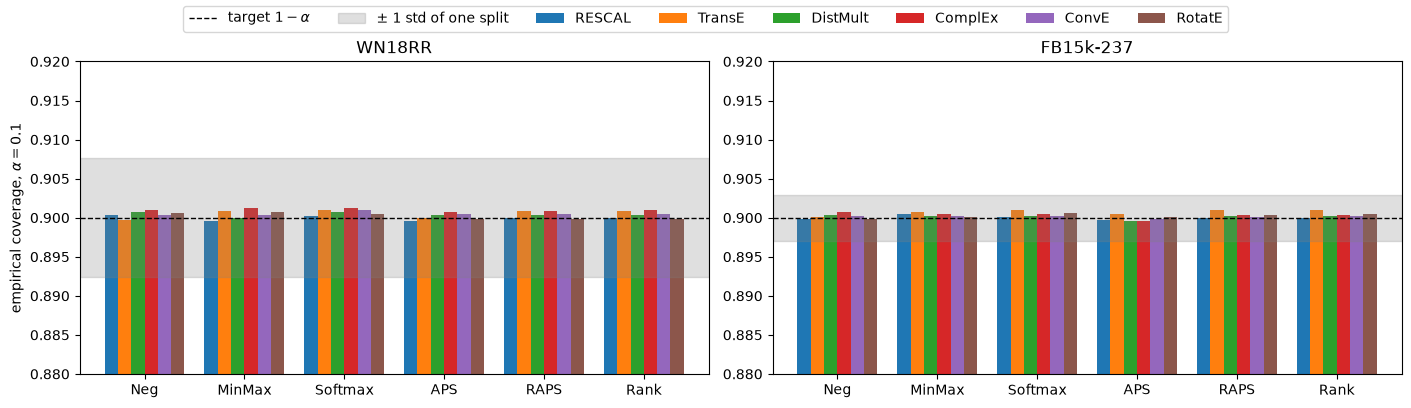

score                 Neg MinMax Softmax    APS   RAPS   Rank
dataset   model                                              
WN18RR    RESCAL    0.900  0.900   0.900  0.900  0.900  0.900
          TransE    0.900  0.901   0.901  0.900  0.901  0.901
          DistMult  0.901  0.900   0.901  0.900  0.900  0.900
          ComplEx   0.901  0.901   0.901  0.901  0.901  0.901
          ConvE     0.900  0.900   0.901  0.900  0.900  0.900
          RotatE    0.901  0.901   0.901  0.900  0.900  0.900
FB15k-237 RESCAL    0.900  0.900   0.900  0.900  0.900  0.900
          TransE    0.900  0.901   0.901  0.900  0.901  0.901
          DistMult  0.900  0.900   0.900  0.900  0.900  0.900
          ComplEx   0.901  0.900   0.900  0.900  0.900  0.900
          ConvE     0.900  0.900   0.900  0.900  0.900  0.900
          RotatE    0.900  0.900   0.901  0.900  0.900  0.900

In [4]:
plot_coverage(["WN18RR", "FB15k-237"])

Coverage is on target again, 0.900 to 0.901 for every model and score: the guarantee does not depend on how hard the dataset is or how good the model is. Rank no longer over-covers, since its $k$ is now in the hundreds or thousands.

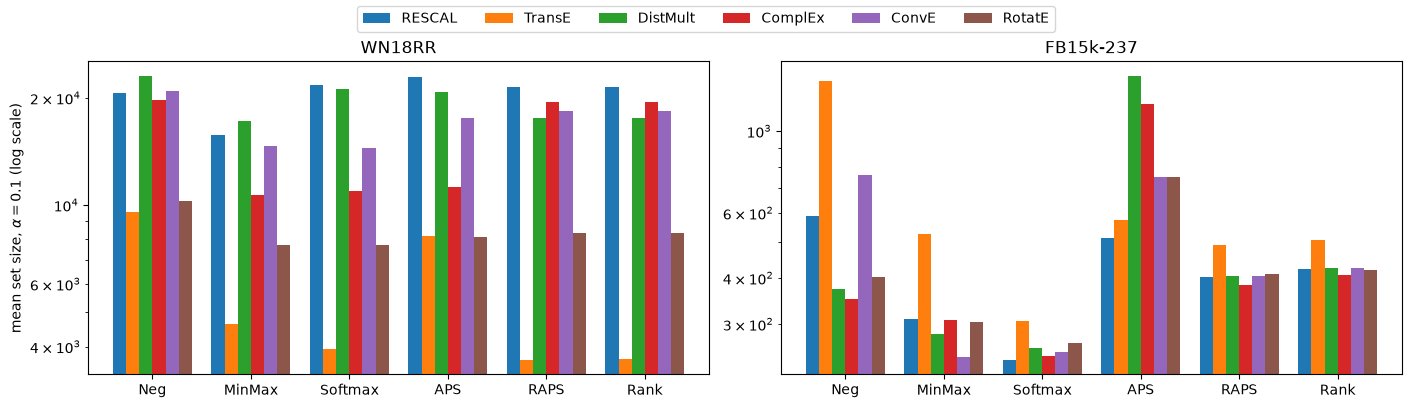

score                    Neg    MinMax   Softmax       APS      RAPS      Rank
dataset   model                                                               
WN18RR    RESCAL    20,634.6  15,735.7  21,804.4  22,879.9  21,520.3  21,521.4
          TransE     9,531.0   4,641.3   3,937.3   8,205.8   3,673.6   3,683.2
          DistMult  23,103.2  17,183.4  21,157.6  20,810.4  17,544.9  17,542.2
          ComplEx   19,723.4  10,656.0  10,934.8  11,259.3  19,492.2  19,498.0
          ConvE     20,885.8  14,643.5  14,424.2  17,519.2  18,389.3  18,392.5
          RotatE    10,253.4   7,698.8   7,716.6   8,106.7   8,317.6   8,319.6
FB15k-237 RESCAL       589.8     309.9     240.2     512.5     401.7     421.9
          TransE     1,365.5     526.6     306.1     575.0     489.9     508.0
          DistMult     374.2     282.6     258.0   1,412.6     405.2     425.7
          ComplEx      351.0     306.8     245.4   1,182.5     383.5     407.0
          ConvE        759.7     244.0     251.7     748.6     404.6     425.9
          RotatE       403.0     304.4     266.4     750.3     410.9     420.1

In [5]:
plot_size(["WN18RR", "FB15k-237"])

The guarantee costs far more here:

- **WN18RR:** with each model's best score, a set holds 3,674 to 17,183 of the 40,943 entities, 9% to 42% of the graph. For ComplEx with Softmax, that is 10,935 entities, against 1.2 on WN18.
- **FB15k-237:** 240 to 306 of the 14,541 entities with the best score, about 2% of the graph. For ComplEx with Softmax, 245 against 22 on FB15k.
- **The best score varies on WN18RR:** MinMax for four models, Softmax for ConvE (2% below MinMax) and RAPS for TransE. On FB15k-237, Softmax is the best score or within 3% of it for every model.
- **Model accuracy is a poor guide.** On WN18RR, TransE has by far the lowest test MRR (0.228, against 0.44 to 0.48 for the others) and the smallest sets (3,674 entities with RAPS), while RESCAL and DistMult, with MRRs of 0.467 and 0.452, have the largest. The set size follows the worst-ranked queries, not the typical ones, as the last part shows.

In [6]:
# Softmax set sizes at the three alphas of scripts/conformal.py
softmax = results[(results.groups == "marginal") & (results.score == "Softmax")]
by_alpha = softmax.pivot(index=["dataset", "model"], columns="alpha", values="size")
by_alpha = by_alpha.loc[pd.MultiIndex.from_product([DATASETS.values(), MODELS.values()])]
by_alpha["0.1 / 0.2"] = by_alpha[0.1] / by_alpha[0.2]
by_alpha.map("{:,.1f}".format)

alpha                   0.05       0.1      0.2 0.1 / 0.2
dataset   model                                          
WN18      RESCAL         3.5       1.2      0.9       1.4
          TransE       589.6     258.0     21.9      11.8
          DistMult       2.6       1.1      0.8       1.4
          ComplEx        3.5       1.2      1.0       1.2
          ConvE          2.3       1.1      0.8       1.3
          RotatE        11.5       1.1      0.9       1.3
FB15k     RESCAL       119.5      45.8     15.8       2.9
          TransE     1,459.6     317.3     26.8      11.8
          DistMult      58.9      19.2      5.1       3.7
          ComplEx       66.4      21.8      5.3       4.1
          ConvE         66.8      21.5      5.5       3.9
          RotatE       108.3      29.7      7.5       3.9
WN18RR    RESCAL    31,129.8  21,804.4  8,707.6       2.5
          TransE    10,935.6   3,937.3    516.1       7.6
          DistMult  30,085.8  21,157.6  6,662.4       3.2
          ComplEx   17,381.1  10,934.8  2,964.4       3.7
          ConvE     24,209.5  14,424.2  6,226.2       2.3
          RotatE    18,572.4   7,716.6    854.1       9.0
FB15k-237 RESCAL       465.0     240.2     94.8       2.5
          TransE       551.8     306.1    130.4       2.3
          DistMult     472.7     258.0    105.3       2.5
          ComplEx      464.4     245.4     99.6       2.5
          ConvE        437.7     251.7    112.1       2.2
          RotatE       473.1     266.4    108.8       2.4

With $\alpha = 0.2$ instead of 0.1, Softmax sets shrink by a factor of 1.2 to 1.4 on WN18, 2.9 to 4.1 on FB15k (11.8 for TransE on both) and 2.2 to 2.5 on FB15k-237. WN18RR's shrink the most, by 2.3 to 9.0: RotatE's sets drop from 7,717 to 854 entities. The extra 10% of coverage costs most where some queries' true answers are ranked almost at random, which is the subject of the next part.

## Why the harder versions need large sets

Three observations explain the gap. The first needs only the datasets, the other two four of the models, ComplEx on each dataset.

**To run this part**, download the four datasets and the four ComplEx models (260 MB) from the repository root:

```bash
uv run scripts/download_data.py wn18 fb15k wnrr fb15k-237
B=https://web.informatik.uni-mannheim.de/pi1
mkdir -p models/libkge
for n in fb15k-237-complex wnrr-complex; do curl -fL -o models/libkge/$n.pt $B/iclr2020-models/$n.pt; done
for n in fb15k-complex wn18-complex; do curl -fL -o models/libkge/$n.pt $B/libkge-models/$n.pt; done
shasum -a 256 models/libkge/*-complex.pt
```

The checksums should be:

```
a3c26e5efef69a672470d2bdc48cd4e83473367c888d0bc1adc00229bcb5d0de  models/libkge/fb15k-237-complex.pt
3334a0aad7b279bd93090cb39bd7d52b61aabbc55ebcc96ff219cea1abc0e840  models/libkge/fb15k-complex.pt
63acd1833782ae3883a95be86a4c6dd66fb9d8df1e37c8327a2002209edabce8  models/libkge/wn18-complex.pt
c53aa7503b0d5c68f3f4ea3f705b5e21c209c1f7e1fe9fbd47fccf23cdb0e68f  models/libkge/wnrr-complex.pt
```

LibKGE's other 20 models are in the same two places: `iclr2020-models/` has RESCAL, TransE, DistMult, ComplEx and ConvE on FB15k-237 and WN18RR, and `libkge-models/` has RotatE on these two and all six models on FB15k and WN18, named `<dataset>-<model>.pt` as above. They are linked from [LibKGE's README](https://github.com/uma-pi1/kge#results-and-pretrained-models). With all 24, `scripts/conformal.py` reproduces `results/conformal/libkge/` (on a GPU; see the top of this notebook).

### 1. Shortcuts in WN18 and FB15k

How many test triples $(s, p, o)$ have their reverse pair $(o, \cdot, s)$, under any relation, in the training data, and how many contain an entity that no training triple contains:

In [7]:
DATA = ROOT / "third_party/libkge/data"


def triples(dataset: str, split: str) -> pd.DataFrame:
    return pd.read_csv(DATA / dataset / f"{split}.del", sep="\t", names=["s", "p", "o"])


rows = {}
for key, name in DATASETS.items():
    train, test = triples(key, "train"), triples(key, "test")
    pairs = set(zip(train.s, train.o, strict=True))
    seen = set(train.s) | set(train.o)
    test_pairs = list(zip(test.s, test.o, strict=True))
    rows[name] = {
        "test triples": len(test),
        "reverse pair in train": sum((o, s) in pairs for s, o in test_pairs) / len(test),
        "entity not in train": sum(s not in seen or o not in seen for s, o in test_pairs)
        / len(test),
    }
shortcuts = pd.DataFrame(rows).T
shortcuts.style.format(
    {"test triples": "{:,.0f}", "reverse pair in train": "{:.1%}", "entity not in train": "{:.1%}"}
)

,test triples,reverse pair in train,entity not in train
WN18,"5,000",94.0%,0.0%
FB15k,"59,071",77.6%,0.0%
WN18RR,"3,134",34.9%,6.7%
FB15k-237,"20,466",0.0%,0.1%


94% of WN18's test triples and 78% of FB15k's have their reverse pair in the training data, such as $(y, \text{hypernym}, x)$ for a test triple $(x, \text{hyponym}, y)$. A model that learns these reverse relations answers most test queries with its top candidate. The harder versions remove such triples, and FB15k-237 has none left. WN18RR still has them for 35% of its test triples, since it keeps WordNet's symmetric relations, such as *derivationally related form*.

WN18RR also has a difficulty of its own: 6.7% of its test triples contain an entity that appears in no training triple, so its embedding was never trained.

### 2. The set size is the rank of the hardest tenth

A set with coverage 0.9 must hold the true answer of 90% of the queries, so its size depends on how deep the true answers of the worst 10% lie, not on the median rank or the MRR. The Rank score makes this exact: its set is the top $\hat k$ candidates of every query, where $\hat k$ is the conformal quantile of the calibration queries' ranks, about the 90th percentile of the rank of the true answer.

We compute the rank of each test query's true answer for ComplEx, among the same candidates as conformal prediction: the answers known from train and valid are removed, other test answers are kept (their number is the last column).

In [8]:
DEVICE = "cpu"  # or "cuda", "mps"


@torch.no_grad()
def true_ranks(model: kgcp.LibKGE, queries: kgcp.Queries, known: kgcp.KnownAnswers) -> torch.Tensor:
    # rank of each query's true answer among its candidates (1 = best)
    ranks = []
    for start in range(0, len(queries), 1024):
        batch = queries[start : start + 1024]
        logits = model.score(batch).masked_fill(known(batch).to(DEVICE), -torch.inf)
        true = logits[torch.arange(len(batch)), batch.target]
        ranks.append(1 + (logits > true[:, None]).sum(1).cpu())
    return torch.cat(ranks).double()


models, queries, ranks, rows = {}, {}, {}, {}
for key, name in DATASETS.items():
    with contextlib.redirect_stderr(io.StringIO()):  # LibKGE's notes on renamed options
        models[name] = kgcp.LibKGE(ROOT / "models/libkge" / f"{key}-complex.pt", device=DEVICE)
    kg = models[name].kg
    queries[name] = q = kgcp.Queries.from_triples(kg.split("test"))
    ranks[name] = r = true_ranks(models[name], q, kg.known("train", "valid"))
    other = kg.known("test")  # the other test answers of a query
    sizes = marginal[(marginal.dataset == name) & (marginal.model == "ComplEx")].set_index("score")[
        "size"
    ]
    rows[name] = {
        "Hits@1": (r <= 1).double().mean().item(),
        "Hits@10": (r <= 10).double().mean().item(),
        "median rank": r.median().item(),
        "80% rank": r.quantile(0.8).item(),
        "90% rank": r.quantile(0.9).item(),
        "95% rank": r.quantile(0.95).item(),
        "Rank set size": sizes["Rank"],
        "Softmax set size": sizes["Softmax"],
        "other test answers": sum(
            other(q[i : i + 1024]).sum().item() for i in range(0, len(q), 1024)
        )
        / len(q),
    }
pd.DataFrame(rows).T.style.format("{:,.0f}").format("{:.3f}", subset=["Hits@1", "Hits@10"]).format(
    "{:,.1f}", subset=["Rank set size", "Softmax set size", "other test answers"]
)

,Hits@1,Hits@10,median rank,80% rank,90% rank,95% rank,Rank set size,Softmax set size,other test answers
WN18,0.858,0.953,1,1,2,9,2.0,1.2,0.6
FB15k,0.504,0.799,1,11,52,185,51.8,21.8,17.8
WN18RR,0.423,0.546,4,"4,281","19,533","24,530","19,498.0","10,934.8",0.5
FB15k-237,0.210,0.500,10,139,406,842,407.0,245.4,21.9


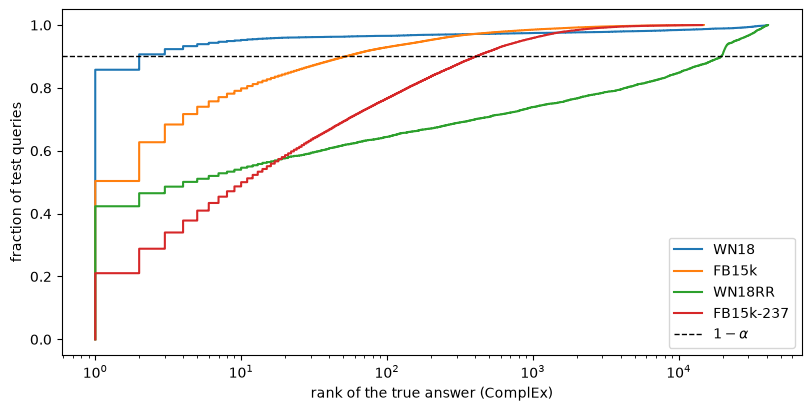

In [9]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for name, r in ranks.items():
    x = r.sort().values
    ax.step(x, torch.arange(1, len(x) + 1) / len(x), where="post", label=name)
ax.axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1, label=r"$1 - \alpha$")
ax.set(xscale="log", xlabel="rank of the true answer (ComplEx)", ylabel="fraction of test queries")
ax.legend(loc="lower right")
plt.show()

- **The 90th percentile of the ranks is the Rank set size:** 2, 52, 19,533 and 406 here, against Rank sets of 2.0, 51.8, 19,498 and 407 entities on average over the 100 splits.
- **The median does not show the difference.** The median rank is 1 to 10 on all four graphs, and it is even larger on FB15k-237 (10) than on WN18RR (4). But the 90th percentile is 406 on FB15k-237 and 19,533 on WN18RR, about half of its entities.
- **The curves show why.** WN18 reaches 0.9 at rank 2 and FB15k at rank 52. FB15k-237 rises steadily and reaches 0.9 at rank 406. WN18RR rises quickly to half of the queries (median rank 4), then slowly, and reaches 0.9 only after a jump near rank 20,000, from queries with an unseen entity (part 3).
- **Softmax** adapts the set to the query and needs fewer candidates than Rank on the hard graphs (10,935 against 19,498 on WN18RR, 245 against 407 on FB15k-237), but it still has to reach the same hard queries.
- **Other test answers.** Hits@1 and Hits@10 are lower here than in LibKGE's evaluation (FB15k: Hits@10 0.799 against 0.892), because conformal prediction keeps a query's other test answers as candidates: 17.8 per query on FB15k, 21.9 on FB15k-237. They are correct answers too, and they count in the set size.

### 3. WN18RR: shortcut, no shortcut, or an unseen entity

WN18RR's test queries fall into three groups: those whose triple has its reverse pair in train, those with an entity that no training triple contains, and the others.

In [10]:
name = "WN18RR"
kg, q, r = models[name].kg, queries[name], ranks[name]
train = kg.split("train")
pairs = set(zip(train[:, 0].tolist(), train[:, 2].tolist(), strict=True))
reverse = torch.tensor([(o, s) in pairs for s, _, o in kg.split("test").tolist()]).repeat(2)
seen = torch.zeros(kg.num_entities, dtype=torch.bool)
seen[train[:, [0, 2]].flatten()] = True
unseen = ~(seen[q.anchor] & seen[q.target])  # tail queries, then head queries, as `reverse`

wnrr = pd.DataFrame({"relation": [kg.relations[i] for i in q.relation.tolist()], "rank": r.numpy()})
wnrr["reverse pair in train"], wnrr["entity not in train"] = reverse.numpy(), unseen.numpy()
wnrr["group"] = "no shortcut"
wnrr.loc[wnrr["reverse pair in train"], "group"] = "reverse pair in train"
wnrr.loc[wnrr["entity not in train"], "group"] = "entity not in train"


def summary(group: pd.DataFrame) -> pd.Series:
    return pd.Series(
        {
            "queries": len(group),
            "share": len(group) / len(wnrr),
            "Hits@10": (group["rank"] <= 10).mean(),
            "median rank": group["rank"].median(),
            "90% rank": group["rank"].quantile(0.9),
        }
    )


groups = wnrr.groupby("group")[["rank"]].apply(summary)
easy = groups.loc["reverse pair in train", "share"]
needed = (1 - ALPHA - easy) / (1 - easy)  # coverage the other queries need for 0.9 overall
rank = wnrr[wnrr.group != "reverse pair in train"]["rank"].quantile(needed)
print(f"the other queries need coverage {needed:.3f}: their {needed:.0%} rank is {rank:,.0f}")
groups.style.format("{:,.0f}").format("{:.1%}", subset=["share"]).format(
    "{:.3f}", subset=["Hits@10"]
)

the other queries need coverage 0.846: their 85% rank is 19,533


,queries,share,Hits@10,median rank,90% rank
group,,,,,
entity not in train,420,6.7%,0.000,"20,378","32,061"
no shortcut,"3,658",58.4%,0.341,90,"17,731"
reverse pair in train,"2,190",34.9%,0.994,1,1


In [11]:
relations = wnrr.groupby("relation").agg(
    queries=("rank", "size"),
    reverse_pair_in_train=("reverse pair in train", "mean"),
    entity_not_in_train=("entity not in train", "mean"),
    median_rank=("rank", "median"),
    rank_90=("rank", lambda x: x.quantile(0.9)),
)
relations.sort_values("queries", ascending=False).style.format("{:,.0f}").format(
    "{:.0%}", subset=["reverse_pair_in_train", "entity_not_in_train"]
)

,queries,reverse_pair_in_train,entity_not_in_train,median_rank,rank_90
relation,,,,,
_hypernym,"2,502",0%,15%,"1,186","24,780"
_derivationally_related_form,"2,148",94%,0%,1,1
_member_meronym,506,1%,3%,21,943
_has_part,344,1%,2%,68,"9,636"
_instance_hypernym,244,0%,8%,7,"10,353"
_synset_domain_topic_of,228,0%,4%,36,"19,692"
_also_see,112,70%,0%,1,"7,768"
_verb_group,78,97%,0%,1,1
_member_of_domain_region,52,0%,0%,"2,298","21,474"


- **Reverse pair in train (35% of the queries):** answered by the top candidate almost always (median and 90th percentile rank 1, Hits@10 0.994). These are WN18RR's symmetric relations: *derivationally related form*, *verb group*, *similar to*, and most of *also see*.
- **Entity not in train (6.7%):** no better than chance, Hits@10 0. When the true answer is the unseen entity, its untrained embedding scores about the same for every query, and the answer lands near rank 20,000 of 40,943: most of the queries in the jump of the curve above.
- **No shortcut (58%):** median rank 90, but a 90th percentile of 17,731. *Hypernym*, 40% of all queries, is the hardest large relation: median rank 1,186, 90th percentile 24,780, and 15% of its queries have an unseen entity.

The first group is covered by sets of one entity. To reach 0.9 overall, the sets must cover $(0.9 - 0.349) / (1 - 0.349) \approx 85\%$ of the other two groups, and the 85th percentile of their ranks is 19,533, the 90th percentile of all queries above.

How much do the queries with an unseen entity cost? Softmax sets for ComplEx, calibrated as above on 100 random splits of all test queries, then of the test queries without them:

In [12]:
scores = kgcp.nonconformity(models[name], q, kgcp.Softmax(), kg.known("train", "valid"))
rows = []
for label, subset in [
    ("all queries", scores),
    ("without entities not in train", scores[torch.nonzero(~unseen).flatten()]),
]:
    for split in range(100):
        cal, test = subset.split(0.5, torch.Generator().manual_seed(split))
        sets = kgcp.SplitConformal(ALPHA).calibrate(cal).predict(test)
        new = ~(seen[test.queries.anchor] & seen[test.queries.target])
        rows.append(
            {
                "queries": label,
                "coverage": sets.covered.double().mean().item(),
                "set size": sets.size.double().mean().item(),
                "coverage, entity not in train": sets.covered[new].double().mean().item()
                if new.any()
                else math.nan,
                "coverage, other queries": sets.covered[~new].double().mean().item(),
            }
        )
pd.DataFrame(rows).groupby("queries", sort=False).mean().style.format("{:.3f}").format(
    "{:,.0f}", subset=["set size"]
)

,coverage,set size,"coverage, entity not in train","coverage, other queries"
queries,,,,
all queries,0.901,"10,935",0.545,0.927
without entities not in train,0.900,"6,463",nan,0.900


With all queries, marginal calibration covers 93% of the queries whose entities were all seen in training and 55% of those with an unseen entity: to make up for the random ones, the threshold reaches further into every query's candidates. Without these 420 queries (6.7%), the same procedure gives sets of 6,463 entities instead of 10,935, 41% fewer. They are still large: the queries without a shortcut, mostly *hypernym*, need the rest.

## Takeaways

- **Coverage holds everywhere.** For all 24 models and six scores, the coverage is within one standard deviation of a split from 0.9, apart from Rank's over-coverage on WN18 (integer $k$). It depends neither on the dataset nor on the model's accuracy.
- **The set size is the price of the hardest queries.** At coverage $1 - \alpha$, a set must reach the true answers of all but the worst $\alpha$ of the queries. WN18 and FB15k look easy because most of their test triples have their reverse in the training data. On FB15k-237 and WN18RR, the 90th percentile rank of the true answer is 406 and 19,533 for ComplEx, and the sets follow it.
- **WN18RR's sets are huge for two reasons:** 58% of its queries have no shortcut, mostly *hypernym*, and 6.7% contain an entity whose embedding was never trained, and their answers are ranked at random. Without the latter, the sets shrink by 41%.
- **MRR and Hits@k do not predict set size:** on WN18RR, the least accurate model, TransE, has the smallest sets.
- **Scores:** Softmax, or MinMax, remains a good default, as on the small graphs. APS gives sets of thousands of entities on graphs this large, and RAPS repairs much of it. TransE does best with Rank or RAPS.
- **On the hard graphs**, smaller sets need a larger $\alpha$, or calibration per group of queries, so that the hardest queries do not inflate every set: per relation (`kgcp.by_relation`, see [docs/conformal_prediction.md](../docs/conformal_prediction.md)), or a custom grouping that separates the queries with an unseen entity.